# E-Commerce Sales Analysis

**Dataset:** [Online Retail / E-Commerce Data — Kaggle](https://www.kaggle.com/datasets/carrie1/ecommerce-data)  
**Tools:** Python · Pandas · Matplotlib · Seaborn  
**Period:** December 2010–December 2011 (December 2011 is incomplete)

**Objective:** Analyze online retail transactions to understand revenue performance, leading markets and products, seasonality, and customer purchasing behavior. Results are based on a filtered, deduplicated sales-only dataset; exclusions and limitations are documented below.

## 1. Load data and understand the columns
**InvoiceNo:** invoice identifier; IDs starting with `C` are cancellations. **StockCode:** stock/item code. **Description:** item text. **Quantity:** number of units. **InvoiceDate:** order date and time. **UnitPrice:** unit price (GBP). **CustomerID:** customer identifier (can be missing). **Country:** customer country.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
Path("figures").mkdir(exist_ok=True)

In [2]:
# Run this notebook from the project root and download data.csv from Kaggle if needed.
csv_path = Path("data.csv")
if not csv_path.is_file():
    raise FileNotFoundError(
        "data.csv not found. Download the original Kaggle/UCI Online Retail data "
        "and save it in the project root (see README.md)."
    )

df = pd.read_csv(
    csv_path, encoding="latin1", low_memory=False,
    dtype={"InvoiceNo": "string", "StockCode": "string"},
)
print("Raw rows and columns:", df.shape)
display(df.head())

Raw rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
print("Columns and types:")
display(df.dtypes)
print("Missing values in raw data:")
display(df.isna().sum())
print("Exact duplicate rows in raw data:", df.duplicated().sum())
print("Unique invoices:", df["InvoiceNo"].nunique())
print("Unique customers (known):", df["CustomerID"].nunique())

Columns and types:


InvoiceNo      string[python]
StockCode      string[python]
Description            object
Quantity                int64
InvoiceDate            object
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

Missing values in raw data:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Exact duplicate rows in raw data: 5268
Unique invoices: 25900
Unique customers (known): 4372


## 2. Clean the sales data
**Sales-only analysis rules:** exclude cancellation invoices (`InvoiceNo` starts with `C`) and non-positive quantity/price lines. Keep unknown `CustomerID` for overall sales analysis; drop it only for customer-level analysis.

**Duplicates:** create an analysis copy without exact duplicate rows but preserve the pre-deduplication copy for a sensitivity comparison. Identical rows are *not proven errors*; results that exclude them are one analytical scenario.

**Product ranking:** exclude `DOT` (Dotcom postage), `POST` (postage) and `M` (manual entries) in the product-only dataset. Other special codes may require future review.

In [4]:
# Do not overwrite df (raw data).
df_clean = df.loc[
    (~df["InvoiceNo"].str.startswith("C"))
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
].copy()

df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])
df_clean["TotalPrice"] = df_clean["Quantity"] * df_clean["UnitPrice"]
df_clean["Year"] = df_clean["InvoiceDate"].dt.year
df_clean["Month"] = df_clean["InvoiceDate"].dt.month

# Keep both versions to make the duplicate assumption transparent.
df_final = df_clean.drop_duplicates().copy()
df_customers_final = df_final.dropna(subset=["CustomerID"]).copy()
df_products_final = df_final.loc[
    ~df_final["StockCode"].isin(["DOT", "POST", "M"])
].copy()

print("Raw rows:", len(df))
print("Sales rows before deduplication:", len(df_clean))
print("Sales rows after deduplication:", len(df_final))
print("Known-customer sales rows:", len(df_customers_final))

Raw rows: 541909
Sales rows before deduplication: 530104
Sales rows after deduplication: 524878
Known-customer sales rows: 392692


In [5]:
duplicate_count = df_clean.duplicated().sum()
duplicate_revenue = df_clean.loc[df_clean.duplicated(), "TotalPrice"].sum()
duplicate_share = 100 * duplicate_revenue / df_clean["TotalPrice"].sum()

print(f"Exact duplicate rows: {duplicate_count:,}")
print(f"Revenue associated with duplicate copies: £{duplicate_revenue:,.2f}")
print(f"Share of sales-only revenue: {duplicate_share:.2f}%")
print("Missing CustomerID in df_final:", df_final["CustomerID"].isna().sum())
print("Missing CustomerID in df_customers_final:", df_customers_final["CustomerID"].isna().sum())

Exact duplicate rows: 5,226
Revenue associated with duplicate copies: £24,573.74
Share of sales-only revenue: 0.23%
Missing CustomerID in df_final: 132186
Missing CustomerID in df_customers_final: 0


In [6]:
# Final validation: these checks must all pass.
assert df_final.duplicated().sum() == 0
assert (df_final["Quantity"] <= 0).sum() == 0
assert (df_final["UnitPrice"] <= 0).sum() == 0
assert df_final["InvoiceNo"].str.startswith("C").sum() == 0
assert df_customers_final["CustomerID"].isna().sum() == 0
assert df_final["Description"].isna().sum() == 0
print("All final quality checks passed.")
print("df_final shape:", df_final.shape)

All final quality checks passed.
df_final shape: (524878, 11)


## 3. Final KPIs
`Total Orders` counts distinct invoices, not product lines. `Unique Stock Codes` can include service or special transaction codes. `AOV` refers to the mean invoice value in the filtered, deduplicated sales-only dataset (not net profit).

In [7]:
total_revenue = df_final["TotalPrice"].sum()
total_orders = df_final["InvoiceNo"].nunique()
total_customers = df_customers_final["CustomerID"].nunique()
total_stock_codes = df_final["StockCode"].nunique()
aov = total_revenue / total_orders

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Known Customers: {total_customers:,}")
print(f"Unique Stock Codes: {total_stock_codes:,}")
print(f"Average Order Value (AOV): £{aov:,.2f}")

Total Revenue: £10,642,110.80
Total Orders: 19,960
Known Customers: 4,338
Unique Stock Codes: 3,922
Average Order Value (AOV): £533.17


## 4. Country sales
Country revenue share shows how dependent sales are on the biggest geographic market.

In [8]:
country_sales = (
    df_final.groupby("Country", as_index=False)["TotalPrice"]
    .sum()
    .sort_values("TotalPrice", ascending=False)
)
country_sales["RevenueSharePct"] = 100 * country_sales["TotalPrice"] / total_revenue
display(country_sales.head(10))

,Country,TotalPrice,RevenueSharePct
36,United Kingdom,9001744.094,84.586078
24,Netherlands,285446.340,2.682234
10,EIRE,283140.520,2.660567
14,Germany,228678.400,2.148807
13,France,209625.370,1.969772
0,Australia,138453.810,1.301000
31,Spain,61558.560,0.578443
33,Switzerland,57067.600,0.536243
3,Belgium,41196.340,0.387107
32,Sweden,38367.830,0.360528


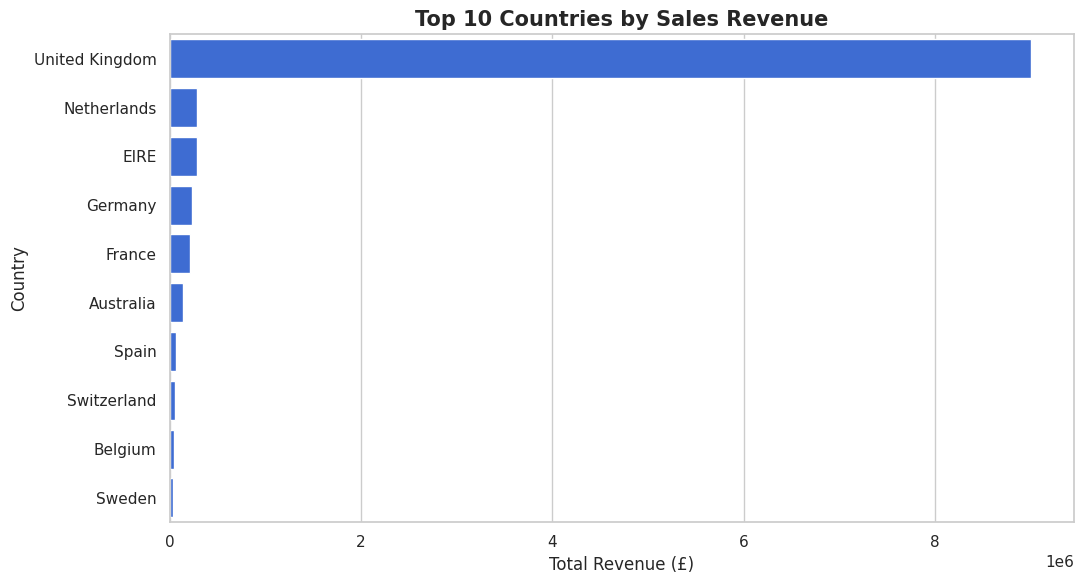

In [9]:
top_countries = country_sales.head(10)
plt.figure(figsize=(11, 6))
sns.barplot(data=top_countries, x="TotalPrice", y="Country", color="#2563eb")
plt.title("Top 10 Countries by Sales Revenue", fontsize=15, fontweight="bold")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig("figures/top_countries_revenue.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Product performance
Use `df_products_final` for product charts, not the broader revenue dataset. Product identity is approximated here by `StockCode`.

In [10]:
top_products_revenue = (
    df_products_final.groupby("StockCode", as_index=False)["TotalPrice"]
    .sum().sort_values("TotalPrice", ascending=False).head(10)
)
top_products_quantity = (
    df_products_final.groupby("StockCode", as_index=False)["Quantity"]
    .sum().sort_values("Quantity", ascending=False).head(10)
)
display(top_products_revenue)
display(top_products_quantity)

,StockCode,TotalPrice
1310,22423,174156.54
2465,23843,168469.60
3407,85123A,104462.75
2670,47566,99445.23
3387,85099B,94159.81
2020,23166,81700.92
1942,23084,66870.03
1006,22086,64875.59
3194,84879,58927.62
2845,79321,54096.36


,StockCode,Quantity
2465,23843,80995
2020,23166,78033
1109,22197,56898
2909,84077,54951
3387,85099B,48371
3407,85123A,37641
439,21212,36396
3194,84879,36362
1942,23084,30739
1374,22492,26633


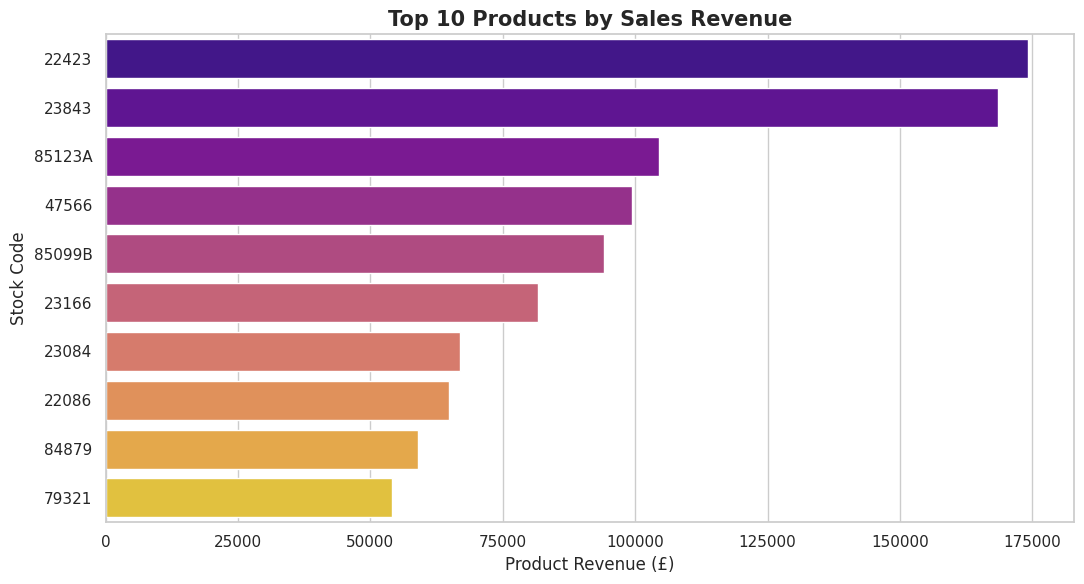

In [11]:
plt.figure(figsize=(11, 6))
sns.barplot(data=top_products_revenue, x="TotalPrice", y="StockCode", hue="StockCode", palette="plasma", dodge=False, legend=False)
plt.title("Top 10 Products by Sales Revenue", fontsize=15, fontweight="bold")
plt.xlabel("Product Revenue (£)")
plt.ylabel("Stock Code")
plt.tight_layout()
plt.savefig("figures/top_products_revenue.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Monthly sales and order trends
Combine year and month into one date so December 2010 and December 2011 remain distinct. **Caution:** December 2011 is only a partial month, so avoid treating its drop as a full-month performance decline.

In [12]:
monthly_sales = (
    df_final.groupby(["Year", "Month"], as_index=False)["TotalPrice"]
    .sum()
)
monthly_sales["Date"] = pd.to_datetime(dict(
    year=monthly_sales["Year"], month=monthly_sales["Month"], day=1
))
monthly_sales = monthly_sales.sort_values("Date")

monthly_orders = (
    df_final.groupby(["Year", "Month"], as_index=False)["InvoiceNo"]
    .nunique().rename(columns={"InvoiceNo": "OrderCount"})
)
monthly_orders["Date"] = pd.to_datetime(dict(
    year=monthly_orders["Year"], month=monthly_orders["Month"], day=1
))
monthly_orders = monthly_orders.sort_values("Date")
display(monthly_sales)
display(monthly_orders)

,Year,Month,TotalPrice,Date
0,2010,12,821452.730,2010-12-01
1,2011,1,689811.610,2011-01-01
2,2011,2,522545.560,2011-02-01
3,2011,3,716215.260,2011-03-01
4,2011,4,536968.491,2011-04-01
5,2011,5,769296.610,2011-05-01
6,2011,6,760547.010,2011-06-01
7,2011,7,718076.121,2011-07-01
8,2011,8,757841.380,2011-08-01
9,2011,9,1056435.192,2011-09-01


,Year,Month,OrderCount,Date
0,2010,12,1559,2010-12-01
1,2011,1,1086,2011-01-01
2,2011,2,1100,2011-02-01
3,2011,3,1454,2011-03-01
4,2011,4,1246,2011-04-01
5,2011,5,1681,2011-05-01
6,2011,6,1533,2011-06-01
7,2011,7,1475,2011-07-01
8,2011,8,1361,2011-08-01
9,2011,9,1837,2011-09-01


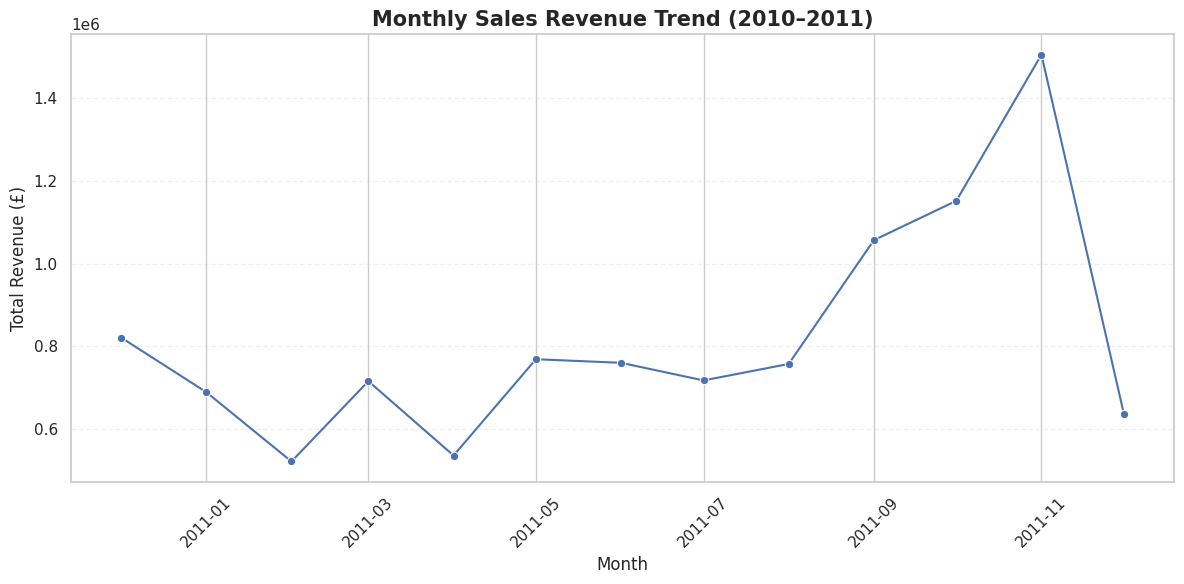

In [13]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_sales, x="Date", y="TotalPrice", marker="o")
plt.title("Monthly Sales Revenue Trend (2010–2011)", fontsize=15, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Total Revenue (£)")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig("figures/monthly_revenue_trend.png", dpi=160, bbox_inches="tight")
plt.show()

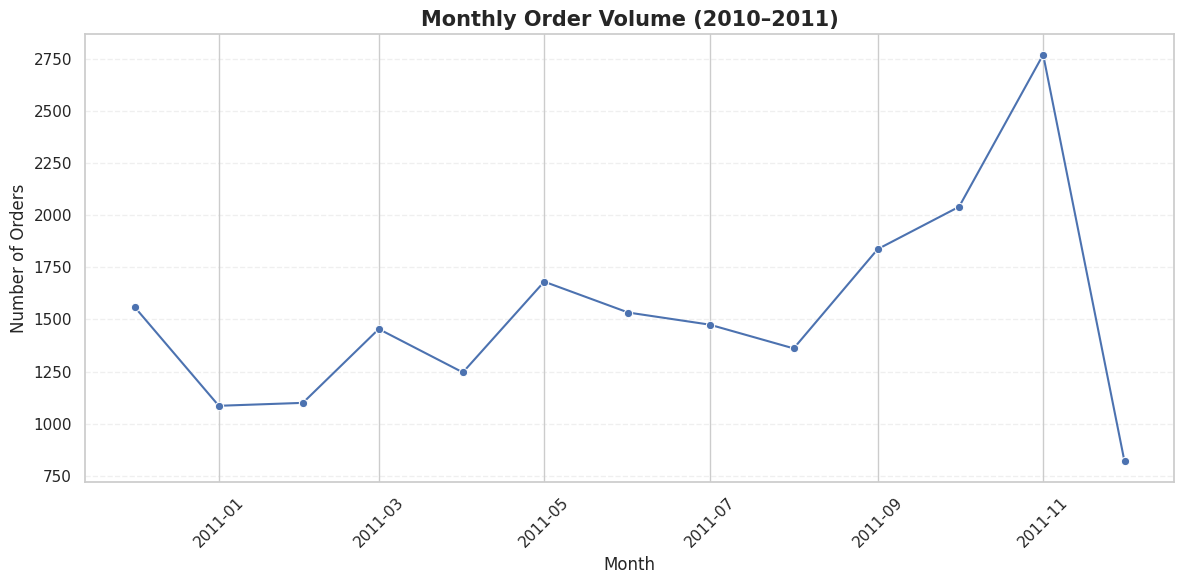

In [14]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_orders, x="Date", y="OrderCount", marker="o")
plt.title("Monthly Order Volume (2010–2011)", fontsize=15, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig("figures/monthly_order_volume.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Customer analysis
Customer KPIs exclude missing `CustomerID`, but those transactions stay in overall revenue. Top spenders and most frequent buyers are different concepts.

In [15]:
top_customers = (
    df_customers_final.groupby("CustomerID", as_index=False)["TotalPrice"]
    .sum().sort_values("TotalPrice", ascending=False).head(10)
)
top_customers["CustomerID"] = top_customers["CustomerID"].astype(int).astype(str)

top_frequent_customers = (
    df_customers_final.groupby("CustomerID", as_index=False)["InvoiceNo"]
    .nunique().rename(columns={"InvoiceNo": "OrderCount"})
    .sort_values("OrderCount", ascending=False).head(10)
)
top_frequent_customers["CustomerID"] = top_frequent_customers["CustomerID"].astype(int).astype(str)

display(top_customers)
display(top_frequent_customers)

,CustomerID,TotalPrice
1689,14646,280206.02
4201,18102,259657.30
3728,17450,194390.79
3008,16446,168472.50
1879,14911,143711.17
55,12415,124914.53
1333,14156,117210.08
3771,17511,91062.38
2702,16029,80850.84
0,12346,77183.60


,CustomerID,OrderCount
326,12748,209
1879,14911,201
4010,17841,124
562,13089,97
1661,14606,93
2176,15311,91
481,12971,86
1689,14646,73
2702,16029,63
795,13408,62


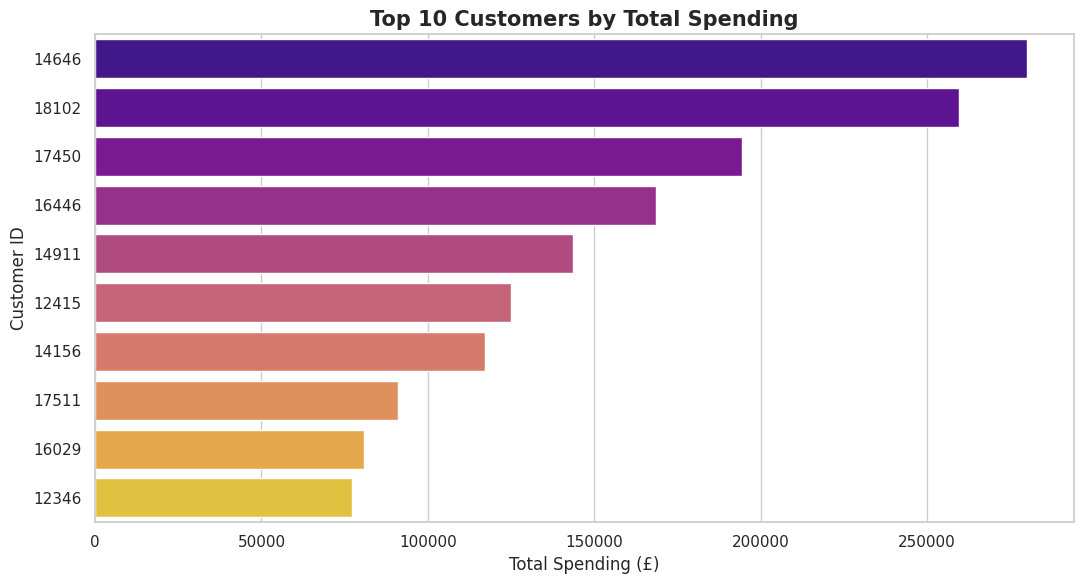

In [16]:
plt.figure(figsize=(11, 6))
sns.barplot(data=top_customers, x="TotalPrice", y="CustomerID", hue="CustomerID", palette="plasma", dodge=False, legend=False)
plt.title("Top 10 Customers by Total Spending", fontsize=15, fontweight="bold")
plt.xlabel("Total Spending (£)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.savefig("figures/top_customers_spending.png", dpi=160, bbox_inches="tight")
plt.show()

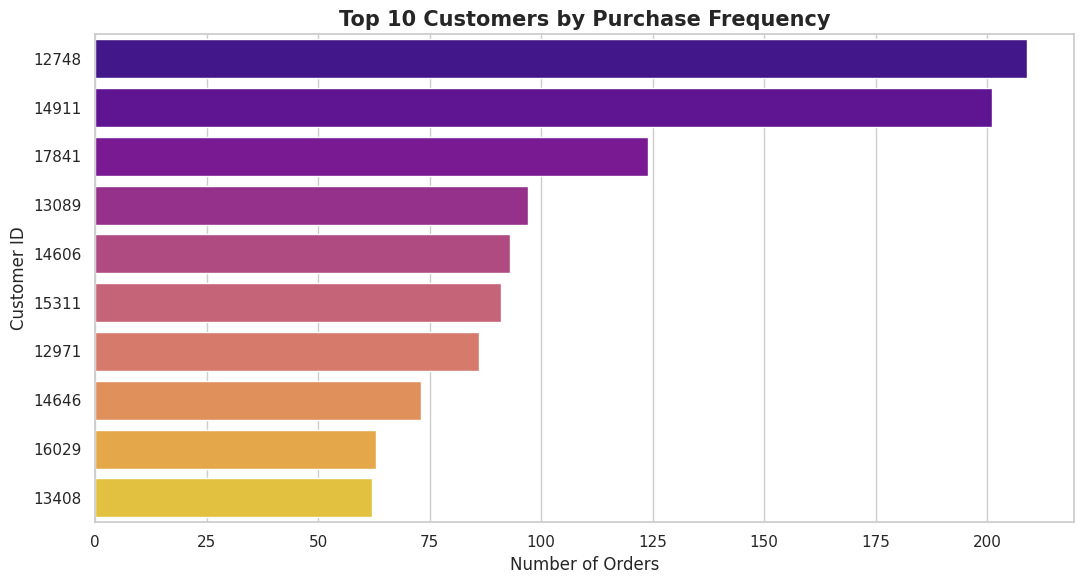

In [17]:
plt.figure(figsize=(11, 6))
sns.barplot(data=top_frequent_customers, x="OrderCount", y="CustomerID", hue="CustomerID", palette="plasma", dodge=False, legend=False)
plt.title("Top 10 Customers by Purchase Frequency", fontsize=15, fontweight="bold")
plt.xlabel("Number of Orders")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.savefig("figures/top_customers_frequency.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Export data for the Streamlit dashboard

The standalone app uses a compressed CSV to avoid repeating the cleaning work on each startup. The export is created from **`df_final`**, so all revenue, order and customer totals remain consistent with the notebook.

Original invoice and customer IDs are replaced by random pseudonyms. Identical IDs map to identical pseudonyms *within each export*, preserving distinct counts. The file is not fully anonymous: transaction details can still be matched to the publicly available source data. Re-running this cell generates new pseudonyms and therefore a new compressed file.

The public repository includes `sales_dashboard.csv.gz` but **does not include** the raw `data.csv` or the local `sales_cleaned.csv`.


In [18]:
# Create a compressed, pseudonymized export for the dashboard.
import uuid

dashboard_columns = [
    "InvoiceNo", "InvoiceDate", "Country", "CustomerID", "StockCode",
    "Description", "Quantity", "UnitPrice", "TotalPrice"
]

dashboard_export = df_final[dashboard_columns].copy()

for column in ("InvoiceNo", "CustomerID"):
    ids = dashboard_export[column].astype("string")
    id_map = {original: uuid.uuid4().hex for original in ids.dropna().unique()}
    dashboard_export[column] = ids.map(id_map)

export_path = Path("sales_dashboard.csv.gz")
dashboard_export.to_csv(export_path, index=False, compression="gzip")
print(f"Saved dashboard data to: {export_path.resolve()}")
print(f"Compressed file size: {export_path.stat().st_size / (1024**2):.1f} MiB")


Saved dashboard data to: /mnt/data/project_review/E-Commerce-Sales-Analysis/sales_dashboard.csv.gz
Compressed file size: 9.0 MiB


In [19]:
# Check the file on disk against the trusted notebook results.
exported = pd.read_csv(
    export_path, compression="gzip",
    dtype={"InvoiceNo": "string", "CustomerID": "string", "StockCode": "string"},
    parse_dates=["InvoiceDate"], low_memory=False,
)

assert len(exported) == len(df_final)
assert exported["InvoiceNo"].nunique() == df_final["InvoiceNo"].nunique()
assert exported["CustomerID"].nunique() == df_final["CustomerID"].nunique()
assert abs(exported["TotalPrice"].sum() - df_final["TotalPrice"].sum()) < 0.01
assert exported["InvoiceNo"].dropna().str.fullmatch(r"[0-9a-f]{32}").all()
assert exported["CustomerID"].dropna().str.fullmatch(r"[0-9a-f]{32}").all()

print(f"Rows: {len(exported):,}")
print(f"Orders: {exported['InvoiceNo'].nunique():,}")
print(f"Known customers: {exported['CustomerID'].nunique():,}")
print(f"Revenue: £{exported['TotalPrice'].sum():,.2f}")
print("Dashboard export validation passed.")


Rows: 524,878
Orders: 19,960
Known customers: 4,338
Revenue: £10,642,110.80
Dashboard export validation passed.


## 9. Key findings and conclusion

This analysis used a **sales-only, deduplicated scenario** to study an online retailer's transaction records. The main findings are:

- **Sales performance:** The final dataset represents **£10,642,110.80** in revenue across **19,960** distinct invoices. The **average order value (AOV)** is **£533.17**.
- **Customer coverage:** **4,338** distinct identified customers appear in the final data. Transactions with missing customer IDs are retained in overall sales reporting, but excluded from customer-level rankings.
- **Market and product concentration:** The **United Kingdom** is the leading sales market. Country and stock-code rankings are calculated from the final dataset, while `DOT`, `POST`, and `M` are omitted only from the product-ranking view.
- **Timing:** The monthly charts show changes in revenue and order volume. **December 2011 is incomplete**, so its total should not be directly compared with full months.
- **Duplicate sensitivity:** Removing **5,226** exact duplicate copies reduces recorded revenue by **£24,573.74** (about **0.23%**). Treating identical rows as duplicates is an *analytical assumption*, not proof that every such row was recorded in error.

### Business implications

The retailer can use the country, product and customer rankings to prioritize market analysis, product assortment review and repeat-customer engagement. The findings describe **revenue, not profit**: the dataset does not supply the costs needed to calculate net profit. Conclusions should be interpreted within the data-cleaning assumptions above.